# Dua mode getaran dalam spektroskopi ultrafast pump–probe
## Tutorial data sintetis, DFT, dan FFT

**Tujuan:** membaca data differential reflectance terhadap time delay, memisahkan osilasi dari latar belakang, dan menemukan dua frekuensi getaran pada orde THz melalui intensitas Fourier. Seluruh data pada tutorial ini **sintetis**, untuk pembelajaran, dan tidak mewakili material tertentu.

Notebook ini sudah berisi keluaran grafik. Untuk mengulang perhitungan, ekstrak seluruh ZIP, buka `pump_probe_fft.ipynb` dari folder paket, lalu pilih **Restart Kernel and Run All Cells**. Data dibaca dari `data/pump_probe_synthetic.csv`; berkas `.dat` memuat angka yang sama dengan pemisah spasi. Pustaka yang diperlukan: NumPy, SciPy, Matplotlib, dan Jupyter.

Alurnya: **fenomena fisika → model matematis → data CSV → grafik waktu → pengurangan latar belakang → FFT → deteksi puncak → pemeriksaan DFT langsung**. Sel kode menampilkan gambar langsung dengan `plt.show()`; PNG terpisah juga disediakan dalam folder `figures`.

## 1. Apa yang diukur dalam pump–probe?

Pulsa **pump** yang sangat singkat mengeksitasi elektron dan dapat membangkitkan getaran kisi secara koheren. Pulsa **probe** datang setelah selang waktu $t$ untuk mengukur perubahan reflektansi. Pengukuran diulangi untuk berbagai time delay, sehingga dinamika yang terlalu cepat untuk diikuti detektor secara langsung dapat direkonstruksi.

Besaran yang kita modelkan adalah

$$
s(t)=\frac{\Delta R(t)}{R_0}=\frac{R_{\text{pump on}}(t)-R_{\text{pump off}}}{R_{\text{pump off}}}.
$$

$R_0$ adalah reflektansi tanpa eksitasi. Nilai $s=10^{-3}$ berarti perubahan reflektansi sebesar $0{,}1\%$. Untuk differential transmission, alur analisis yang sama dapat diterapkan pada $\Delta T/T_0$, dengan model respons optik yang sesuai.

Pada pendekatan perubahan kecil, koordinat getaran $Q_i(t)$ memodulasi sifat optik sehingga kontribusi osilasinya dapat ditulis

$$
s_{\text{osc}}(t)\approx\sum_i g_i Q_i(t),
\qquad g_i=\frac{1}{R_0}\frac{\partial R}{\partial Q_i}.
$$

Mode yang koheren memiliki fase yang teratur terhadap waktu kedatangan pump. Karena itu, kontribusinya tetap muncul ketika pengukuran pada delay yang sama dirata-ratakan. Latar belakang yang berubah lebih lambat dapat berasal dari relaksasi pembawa muatan atau pemanasan.

**Makna sumbu waktu:** $t<0$ berarti probe mendahului pump; $t=0$ adalah pusat tumpang tindih pulsa. Interval sampling pada tutorial ini adalah **langkah time delay**, bukan periode pengulangan laser. Frekuensi THz yang diperoleh adalah frekuensi modulasi respons material terhadap delay.

## 2. Model fisika dan data sintetis

### 2.1 Dua osilator teredam

Salah satu model sederhana untuk koordinat getaran setelah pump adalah osilator harmonik teredam:

$$
\frac{d^2Q_i}{dt^2}+2\Gamma_i\frac{dQ_i}{dt}+\omega_{0i}^2 Q_i=F_i(t).
$$

Setelah gaya eksitasi berakhir, solusi dalam keadaan redaman lemah berbentuk

$$
Q_i(t)=q_i e^{-t/\tau_i}\cos(2\pi f_i t+\phi_i),\qquad t>0.
$$

Di sini $\tau_i=1/\Gamma_i$ adalah waktu peluruhan **amplitudo**, dan $2\pi f_i=\sqrt{\omega_{0i}^2-\Gamma_i^2}$ adalah frekuensi sudut teredam. Jadi, $f_i$ pada tabel berikut merupakan frekuensi osilasi yang diamati. Fase dan amplitudo merangkum kondisi awal serta cara eksitasi dan deteksi.

| Parameter | Mode 1 | Mode 2 |
| --- | ---: | ---: |
| Frekuensi $f_i$ | 2,2 THz | 4,1 THz |
| Periode $1/f_i$ | 0,4545 ps = 454,5 fs | 0,2439 ps = 243,9 fs |
| Amplitudo sebelum respons instrumen $A_i$ | $1{,}00\times10^{-3}$ | $0{,}75\times10^{-3}$ |
| Waktu peluruhan amplitudo $\tau_i$ | 4,0 ps | 3,0 ps |
| Fase $\phi_i$ | 0,20 rad | −0,65 rad |

### 2.2 Latar belakang, instrumen, dan derau

Sebelum respons instrumen diperhitungkan, kita gunakan model kausal

$$
s_{\text{ideal}}(t)=\Theta(t)\left[B e^{-t/\tau_b}+\sum_{i=1}^{2}A_i e^{-t/\tau_i}\cos(2\pi f_i t+\phi_i)\right].
$$

$\Theta(t)$ bernilai 0 sebelum pump dan 1 sejak $t=0$. Dipilih $B=0{,}8\times10^{-3}$ dan $\tau_b=4{,}5$ ps. Model sederhana ini mengabaikan chirp, dinamika spasial, dan respons nonlinear terhadap fluence.

Resolusi waktu instrumen dimodelkan dengan Gaussian ternormalisasi:

$$
G(t)=\frac{1}{\sqrt{2\pi}\sigma_t}\exp\left(-\frac{t^2}{2\sigma_t^2}\right),
\qquad \sigma_t=\frac{0{,}040\ \text{ps}}{2\sqrt{2\ln 2}}.
$$

Lebar 40 fs adalah **FWHM respons instrumen efektif**. Data yang disimpan mengikuti

$$
s_{\text{data}}(t)=C+(G*s_{\text{ideal}})(t)+\epsilon(t),
$$

dengan offset $C=2\times10^{-5}$ dan derau Gaussian independen dengan simpangan baku $2\times10^{-5}$. Konvolusi memuluskan kenaikan sekitar waktu nol dan dapat melemahkan komponen frekuensi tinggi. Lebar ini jauh lebih pendek daripada kedua periode getaran, sehingga keduanya masih dapat diamati.

Sampling dilakukan dari −1 hingga 12 ps dengan $\Delta t=0{,}005$ ps = 5 fs, menghasilkan 2.601 titik. Seed generator acak disimpan agar data dapat direproduksi. Frekuensi yang dipilih adalah contoh pedagogis; referensi di akhir menjelaskan penggunaan osilasi reflektansi dan Fourier dalam eksperimen nyata.

## 3. Dari osilasi waktu ke intensitas Fourier

### 3.1 DFT dan FFT

Setelah latar belakang dikurangi, misalkan terdapat $M$ sampel residual $r_n$ pada delay $t_s+n\Delta t$. Kita bentuk sinyal berjendela $x_n=w_n(r_n-\bar r)$. DFT dengan panjang $N\geq M$ adalah

$$
X_k=\sum_{n=0}^{M-1}x_n\exp\left(-j\frac{2\pi kn}{N}\right),
\qquad f_k=\frac{k}{N\Delta t}.
$$

Sampel tambahan sampai panjang $N$ bernilai nol. **FFT adalah algoritme efisien untuk menghitung DFT yang sama**, sehingga keduanya memberi hasil identik sampai galat pembulatan numerik. Untuk sinyal real, frekuensi negatif merupakan pasangan konjugat frekuensi positif; `np.fft.rfft` cukup untuk menampilkan sisi frekuensi nonnegatif.

Karena $1\ \text{ps}^{-1}=1\ \text{THz}$, memasukkan `d=dt_ps` pada `np.fft.rfftfreq` langsung menghasilkan frekuensi dalam THz. Bila memakai detik, hasilnya Hz dan perlu dibagi $10^{12}$. Dengan langkah 5 fs, frekuensi Nyquist adalah $1/(2\Delta t)=100$ THz.

### 3.2 Apa arti “intensitas Fourier”?

Untuk mendekati transformasi waktu-kontinu, kita definisikan $F_k=\Delta t X_k$. Pergeseran titik awal $t_s$ menambahkan faktor fase $e^{-j2\pi f_k t_s}$, yang tidak mengubah magnitudo. Grafik utama menggunakan kuadrat magnitudo ternormalisasi:

$$
I_k=|F_k|^2,
\qquad I_{\text{rel}}(f_k)=\frac{I_k}{\max_{0{,}5\leq f_l\leq 8\ \text{THz}}I_l}.
$$

$I_k$ memiliki satuan $(\Delta R/R_0)^2 \text{ps}^2$ bila waktu dalam ps; $I_{\text{rel}}$ tidak berdimensi. Istilah **intensitas Fourier** di sini berarti kuadrat magnitudo sinyal, bukan intensitas cahaya dan bukan power spectral density terkalibrasi. Kita menampilkan nilai sisi nonnegatif tanpa menggandakan bin interior; normalisasi relatif tetap sesuai untuk membandingkan kedua puncak di sini.

### 3.3 Mengapa perlu pengolahan awal?

1. **Kurangi latar belakang:** relaksasi eksponensial menghasilkan kontribusi frekuensi rendah yang kuat. Kita fit eksponensial ditambah konstanta langsung pada data setelah 0,25 ps. Nilai latar belakang pembangkit tidak dipakai dalam fit.
2. **Hindari daerah overlap:** gunakan interval 0,25–12 ps agar kenaikan sekitar waktu nol tidak mendominasi analisis getaran.
3. **Kurangi rerata residual:** ini mengurangi komponen DC sebelum windowing.
4. **Kalikan dengan Hann:** ujung data diperkecil untuk mengurangi kebocoran spektral, dengan konsekuensi puncak lebih lebar dan amplitudonya berubah.

Notebook memakai Hann periodik (`sym=False`), dengan rumus

$$
w_n=\frac{1}{2}\left[1-\cos\left(\frac{2\pi n}{M}\right)\right],\qquad n=0,1,\ldots,M-1.
$$

Skala jarak bin DFT tanpa padding adalah $1/(M\Delta t)$, sekitar 0,085 THz. **Zero-padding hanya memperapat grid frekuensi**, sehingga kurva lebih halus; informasi untuk memisahkan mode berdekatan tetap dibatasi durasi pengamatan, redaman, jendela, dan derau. Periode peluruhan juga membuat puncak memiliki lebar hingga, bukan garis delta.

## 4. Persiapan Python

Jika pustaka belum tersedia, jalankan `python -m pip install -r requirements.txt` di terminal. Pilih kernel Python dari lingkungan yang sama, lalu jalankan sel secara berurutan.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import scipy
from scipy.optimize import curve_fit
from scipy.signal import find_peaks, windows
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 120,
    "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.18, "axes.titleweight": "bold",
})
BLUE, ORANGE, GREEN = "#1565a8", "#d96824", "#15827c"
ROOT = Path.cwd()
DATA = ROOT / "data" / "pump_probe_synthetic.csv"
if not DATA.is_file():
    raise FileNotFoundError(
        "CSV tidak ditemukan. Ekstrak seluruh ZIP dan buka notebook dari folder "
        "yang memuat notebook ini dan subfolder data."
    )
print(f"NumPy {np.__version__} | SciPy {scipy.__version__}")

NumPy 2.3.5 | SciPy 1.17.0


## 5. Baca data sintetis dari CSV

CSV utama memuat tepat dua kolom: `delay_ps` dan `deltaR_over_R`. Kolom kedua adalah nilai tak berdimensi, bukan persen. Data mentah mencakup latar belakang, dua osilasi, respons instrumen, dan derau; seluruh analisis utama menggunakan dua kolom ini.

In [2]:
raw = np.genfromtxt(DATA, delimiter=",", names=True)
t = np.asarray(raw["delay_ps"])
y = np.asarray(raw["deltaR_over_R"])
assert np.all(np.isfinite(t)) and np.all(np.isfinite(y))
assert np.all(np.diff(t) > 0), "Time delay harus meningkat."
dt_ps = float(np.mean(np.diff(t)))
assert np.allclose(np.diff(t), dt_ps, rtol=1e-8, atol=1e-12), (
    "FFT biasa memerlukan sampling seragam."
)
assert dt_ps > 0
print(f"Jumlah sampel       : {t.size}")
print(f"Rentang delay       : {t[0]:.3f} sampai {t[-1]:.3f} ps")
print(f"Langkah delay       : {dt_ps:.6f} ps = {dt_ps * 1000:.1f} fs")
print(f"Frekuensi Nyquist   : {1 / (2 * dt_ps):.1f} THz")
print("\nLima baris pertama [delay_ps, deltaR_over_R]:")
print(np.column_stack((t, y))[:5])

Jumlah sampel       : 2601
Rentang delay       : -1.000 sampai 12.000 ps
Langkah delay       : 0.005000 ps = 5.0 fs
Frekuensi Nyquist   : 100.0 THz

Lima baris pertama [delay_ps, deltaR_over_R]:
[[-1.00000000e+00 -1.43277138e-05]
 [-9.95000000e-01  1.47248509e-05]
 [-9.90000000e-01  5.22568931e-06]
 [-9.85000000e-01  1.97658026e-05]
 [-9.80000000e-01  2.40623156e-05]]


## 6. Gambar pertama: sinyal asli terhadap time delay

Panel atas memperlihatkan data yang tersimpan di CSV. Panel bawah memperbesar bagian awal setelah pump, sehingga osilasi dengan gabungan dua periode lebih mudah terlihat. Sumbu vertikal dikalikan $10^3$ hanya untuk memudahkan pembacaan.

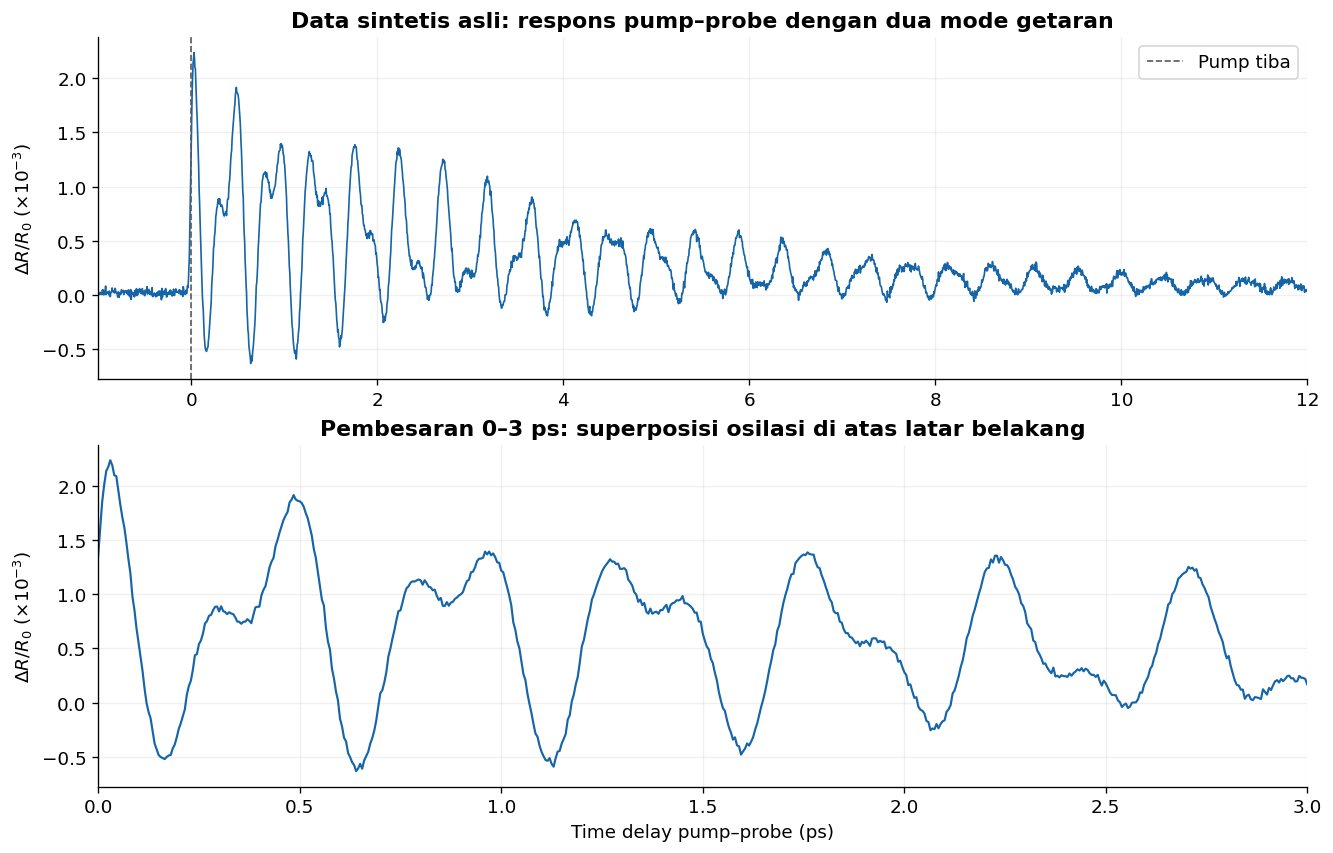

In [3]:
fig_time, ax = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
ax[0].plot(t, 1e3 * y, color=BLUE, lw=1.0)
ax[0].axvline(0, color="0.35", ls="--", lw=1, label="Pump tiba")
ax[0].set(xlim=(-1, 12), ylabel=r"$\Delta R/R_0$ ($\times 10^{-3}$)",
          title="Data sintetis asli: respons pump–probe dengan dua mode getaran")
ax[0].legend(loc="upper right")
ax[1].plot(t, 1e3 * y, color=BLUE, lw=1.3)
ax[1].set(xlim=(0, 3), xlabel="Time delay pump–probe (ps)",
          ylabel=r"$\Delta R/R_0$ ($\times 10^{-3}$)",
          title="Pembesaran 0–3 ps: superposisi osilasi di atas latar belakang")
plt.show()

## 7. Fit dan kurangi latar belakang

Kita gunakan model $b_{\text{fit}}(t)=B_{\text{fit}}e^{-t/\tau_{b,\text{fit}}}+C_{\text{fit}}$. Fit dilakukan pada rentang yang sama dengan FFT, mulai 0,25 ps. Pada rentang ini respons Gaussian di sekitar waktu nol telah berlalu; penjumlahan osilasi yang relatif cepat membuat fit latar belakang sederhana cukup baik untuk contoh ini.

Data dikalikan $10^3$ saat fit untuk memperbaiki skala numerik, lalu hasilnya dikembalikan ke satuan semula. Osilasi sengaja tidak dimasukkan ke model latar belakang. Akibatnya parameter hasil fit dapat sedikit menyimpang dari parameter pembangkit; tujuan langkah ini adalah memperjelas mode getaran, bukan mengestimasi parameter relaksasi dengan presisi tinggi.

In [4]:
analysis_mask = (t >= 0.25 - 1e-10) & (t <= 12.0 + 1e-10)
ta, ya = t[analysis_mask], y[analysis_mask]

def background_milli(t_ps, B_milli, tau_ps, C_milli):
    return B_milli * np.exp(-t_ps / tau_ps) + C_milli

popt, pcov = curve_fit(
    background_milli, ta, 1e3 * ya,
    p0=(0.8, 4.0, 0.02),
    bounds=([0.0, 0.1, -1.0], [10.0, 30.0, 1.0]),
    maxfev=20000,
)
background = 1e-3 * background_milli(ta, *popt)
residual = ya - background
x = residual - residual.mean()
M = x.size
w = windows.hann(M, sym=False)
xw = w * x
print(f"B_fit       = {popt[0] * 1e-3:.6g}")
print(f"tau_bg_fit  = {popt[1]:.4f} ps")
print(f"C_fit       = {popt[2] * 1e-3:.6g}")
print(f"Sampel FFT  = {M}, dari {ta[0]:.2f} sampai {ta[-1]:.2f} ps")

B_fit       = 0.000835064
tau_bg_fit  = 3.7943 ps
C_fit       = 5.13396e-05
Sampel FFT  = 2351, dari 0.25 sampai 12.00 ps


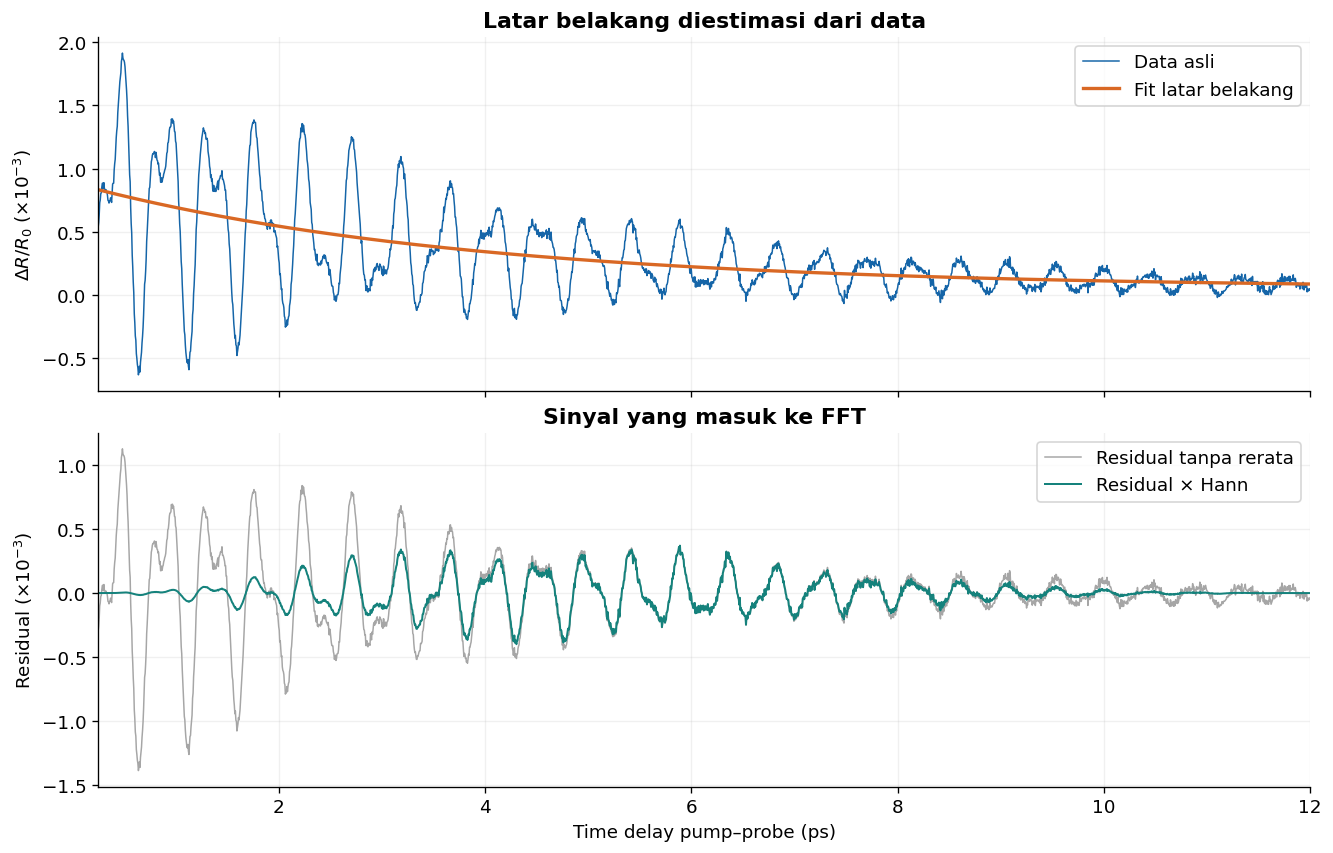

In [5]:
fig_pre, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                           constrained_layout=True)
ax[0].plot(ta, 1e3 * ya, color=BLUE, lw=0.9, label="Data asli")
ax[0].plot(ta, 1e3 * background, color=ORANGE, lw=2, label="Fit latar belakang")
ax[0].set(ylabel=r"$\Delta R/R_0$ ($\times 10^{-3}$)",
          title="Latar belakang diestimasi dari data")
ax[0].legend()
ax[1].plot(ta, 1e3 * x, color="0.65", lw=0.9, label="Residual tanpa rerata")
ax[1].plot(ta, 1e3 * xw, color=GREEN, lw=1.2, label="Residual × Hann")
ax[1].set(xlim=(0.25, 12), xlabel="Time delay pump–probe (ps)",
          ylabel=r"Residual ($\times 10^{-3}$)",
          title="Sinyal yang masuk ke FFT")
ax[1].legend()
plt.show()

## 8. Hitung FFT dan deteksi puncak

`N_fft` dipilih sebagai empat kali pangkat dua terdekat yang tidak lebih kecil daripada $M$. NumPy menambahkan nol otomatis lewat argumen `n`. Deteksi puncak dilakukan pada 0,5–8 THz dengan ambang prominence 0,03 relatif terhadap puncak maksimum; batas ini memisahkan puncak utama dari derau untuk data contoh ini.

Frekuensi asli pembangkit **belum dipakai** dalam langkah ini. Kita mendeteksi seluruh puncak yang memenuhi kriteria, lalu menyimpan dua yang tertinggi. Nilai frekuensi pada tabel hasil adalah posisi bin maksimum, sehingga banyaknya digit yang dicetak tidak menyatakan ketidakpastian eksperimen.

In [6]:
N_fft = 4 * (1 << (M - 1).bit_length())
freq_THz = np.fft.rfftfreq(N_fft, d=dt_ps)
F = dt_ps * np.fft.rfft(xw, n=N_fft)
intensity = np.abs(F) ** 2
band = (freq_THz >= 0.5) & (freq_THz <= 8.0)
I_rel = intensity / intensity[band].max()

band_indices = np.flatnonzero(band)
df_grid = freq_THz[1] - freq_THz[0]
minimum_separation_bins = max(1, int(np.ceil(0.4 / df_grid)))
local_peaks, properties = find_peaks(
    I_rel[band], prominence=0.03, distance=minimum_separation_bins
)
candidate_indices = band_indices[local_peaks]
if candidate_indices.size < 2:
    raise RuntimeError("Kurang dari dua puncak terdeteksi; periksa data atau ambang.")
strongest = candidate_indices[np.argsort(I_rel[candidate_indices])[-2:]]
peak_indices = strongest[np.argsort(freq_THz[strongest])]
peak_frequencies = freq_THz[peak_indices]

print(f"N_fft                         : {N_fft}")
print(f"Jarak bin tanpa zero-padding  : {1 / (M * dt_ps):.6f} THz")
print(f"Jarak grid dengan padding     : {df_grid:.6f} THz")
print(f"Puncak yang lolos kriteria     : {candidate_indices.size}")
print("\nMode | Frekuensi FFT (THz) | Periode (ps) | Intensitas relatif")
for i, k in enumerate(peak_indices, start=1):
    print(f"{i:4d} | {freq_THz[k]:19.6f} | {1/freq_THz[k]:12.6f} | {I_rel[k]:.6f}")

N_fft                         : 16384
Jarak bin tanpa zero-padding  : 0.085070 THz
Jarak grid dengan padding     : 0.012207 THz
Puncak yang lolos kriteria     : 2

Mode | Frekuensi FFT (THz) | Periode (ps) | Intensitas relatif
   1 |            2.197266 |     0.455111 | 1.000000
   2 |            4.101562 |     0.243810 | 0.220385


## 9. Gambar kedua: intensitas Fourier terhadap frekuensi

Dua puncak utama harus terlihat jelas. Panel tambahan memakai skala logaritmik untuk memperlihatkan latar derau. Grafik utama dibatasi 0,5–8 THz agar daerah getaran mudah dibaca; data spektrum lengkap dari 0 hingga Nyquist tetap dihitung dan disediakan dalam CSV hasil.

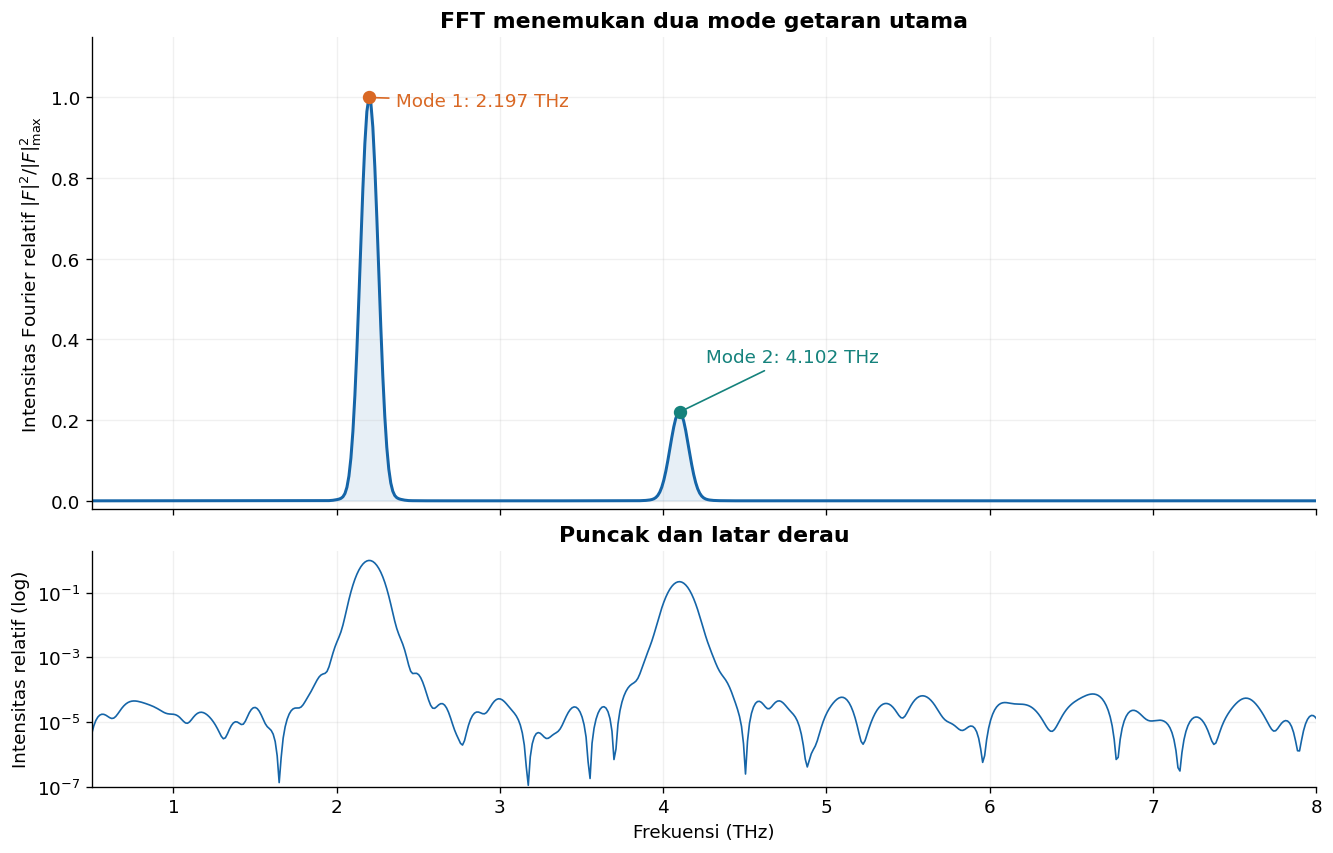

In [7]:
fig_fft, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                           gridspec_kw={"height_ratios": [2, 1]},
                           constrained_layout=True)
ax[0].plot(freq_THz, I_rel, color=BLUE, lw=1.8)
ax[0].fill_between(freq_THz, I_rel, color=BLUE, alpha=0.10)
for i, k in enumerate(peak_indices):
    color = [ORANGE, GREEN][i]
    ax[0].plot(freq_THz[k], I_rel[k], "o", color=color, ms=7)
    ax[0].annotate(f"Mode {i+1}: {freq_THz[k]:.3f} THz",
                   (freq_THz[k], I_rel[k]), xytext=(16, -5 if i == 0 else 30),
                   textcoords="offset points", color=color,
                   arrowprops={"arrowstyle": "-", "color": color})
ax[0].set(ylabel=r"Intensitas Fourier relatif $|F|^2 / |F|^2_{\max}$",
          ylim=(-0.02, 1.15), title="FFT menemukan dua mode getaran utama")
ax[1].semilogy(freq_THz, np.maximum(I_rel, 1e-12), color=BLUE, lw=1)
ax[1].set(xlim=(0.5, 8), ylim=(1e-7, 2), xlabel="Frekuensi (THz)",
          ylabel="Intensitas relatif (log)", title="Puncak dan latar derau")
plt.show()

## 10. Pemeriksaan: DFT langsung memberikan hasil yang sama

Kita evaluasi penjumlahan DFT secara langsung pada beberapa bin, termasuk kedua puncak yang terdeteksi. Ini memakai **seluruh** $M$ sampel yang masuk FFT dan panjang DFT $N$ yang sama. Pemilihan beberapa bin menjaga penggunaan memori tetap kecil; verifikasi ini tidak menghitung ulang seluruh spektrum dengan algoritme kuadratik.

Perhitungan langsung berikut memakai indeks sampel $n$, tanda eksponen negatif, dan faktor $\Delta t$ yang sama dengan FFT. Perbedaan relatif seharusnya mendekati presisi floating point, jauh lebih kecil daripada pengaruh derau pada data.

In [8]:
bins_to_check = np.unique(np.r_[0, 1, peak_indices,
                                peak_indices - 1, peak_indices + 1])
n = np.arange(M)
dft_direct = dt_ps * np.array([
    np.sum(xw * np.exp(-2j * np.pi * k * n / N_fft))
    for k in bins_to_check
])
fft_selected = F[bins_to_check]
relative_error = np.max(np.abs(dft_direct - fft_selected)) / np.max(np.abs(F))
print(f"Jumlah bin yang diperiksa: {bins_to_check.size}")
print(f"Galat maksimum / amplitudo spektrum maksimum: {relative_error:.3e}")
np.testing.assert_allclose(dft_direct, fft_selected, rtol=1e-10, atol=1e-15)
print("Lulus: penjumlahan DFT dan FFT menghasilkan nilai yang sama.")

Jumlah bin yang diperiksa: 8
Galat maksimum / amplitudo spektrum maksimum: 5.363e-15
Lulus: penjumlahan DFT dan FFT menghasilkan nilai yang sama.


## 11. Bandingkan hasil dengan frekuensi pembangkit

Baru sekarang kita membaca metadata sintetis sebagai **ground truth** untuk mengevaluasi hasil. Frekuensi pembangkit tidak menentukan lokasi puncak pada deteksi sebelumnya. Selisih kecil dapat muncul karena sampling grid frekuensi, redaman, panjang rekaman, jendela, estimasi latar belakang, dan derau.

In [9]:
params = json.loads((ROOT / "data" / "parameters.json").read_text())
true_frequencies = np.sort([m["frequency_THz"] for m in params["modes"]])
frequency_errors = peak_frequencies - true_frequencies
table = ["| Mode | Pembangkit (THz) | Puncak FFT (THz) | Selisih (THz) |",
         "| --- | ---: | ---: | ---: |"]
for i, (truth, measured, error) in enumerate(
        zip(true_frequencies, peak_frequencies, frequency_errors), start=1):
    table.append(f"| {i} | {truth:.3f} | {measured:.6f} | {error:+.6f} |")
display(Markdown("\n".join(table)))
assert np.all(np.abs(frequency_errors) < 0.05)
print("Kedua frekuensi berhasil ditemukan dengan selisih kurang dari 0,05 THz.")

Kedua frekuensi berhasil ditemukan dengan selisih kurang dari 0,05 THz.


| Mode | Pembangkit (THz) | Puncak FFT (THz) | Selisih (THz) |
| --- | ---: | ---: | ---: |
| 1 | 2.200 | 2.197266 | -0.002734 |
| 2 | 4.100 | 4.101562 | +0.001563 |

## 12. Percobaan singkat: zero-padding dan jendela

Titik bulat di bawah adalah bin FFT tanpa padding. Garis dengan padding menghubungkan sampling spektrum yang lebih rapat dari rekaman yang sama. Untuk perbandingan ini semua kurva menggunakan **pembagi intensitas yang sama**, yaitu maksimum spektrum Hann berjendela dan ber-padding pada band analisis.

Kurva tanpa Hann juga ditampilkan. Perubahan tinggi dan lebar puncak muncul karena bobot waktu berbeda. Lebar spektrum osilasi yang meluruh berasal pula dari redaman fisik, sehingga seluruh sayap puncak tidak boleh dianggap sebagai kebocoran numerik.

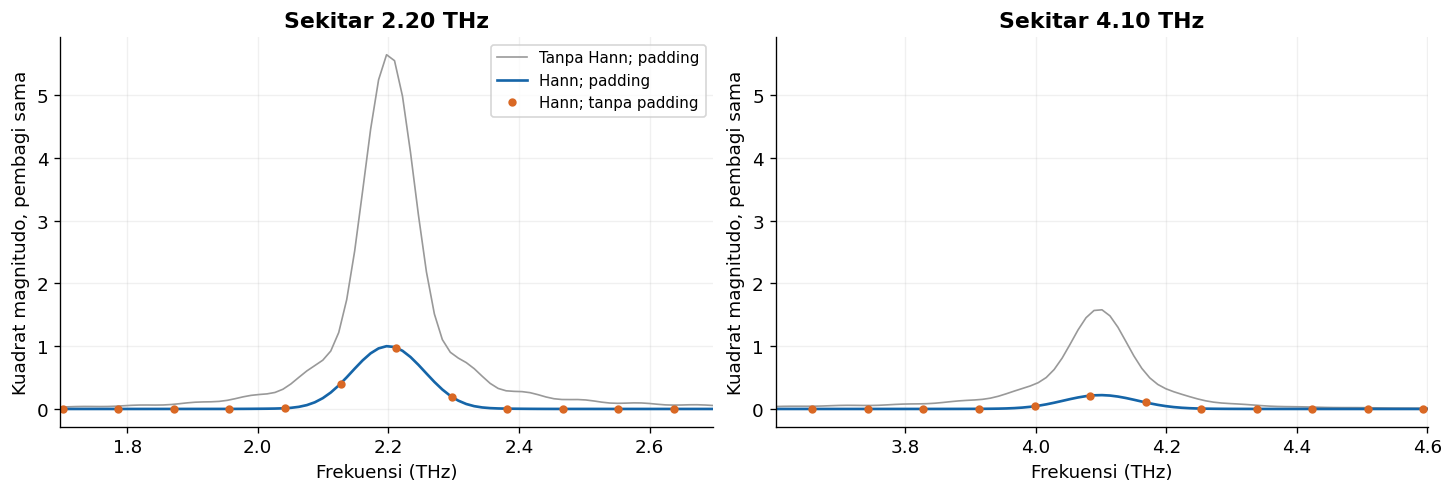

In [10]:
f_native = np.fft.rfftfreq(M, d=dt_ps)
I_native = np.abs(dt_ps * np.fft.rfft(xw)) ** 2 / intensity[band].max()
I_rect = np.abs(dt_ps * np.fft.rfft(x, n=N_fft)) ** 2 / intensity[band].max()
fig_compare, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, center in zip(axes, peak_frequencies):
    ax.plot(freq_THz, I_rect, color="0.6", lw=1, label="Tanpa Hann; padding")
    ax.plot(freq_THz, I_rel, color=BLUE, lw=1.6, label="Hann; padding")
    near = np.abs(f_native - center) < 0.5
    ax.plot(f_native[near], I_native[near], "o", color=ORANGE,
            ms=4, label="Hann; tanpa padding")
    ax.set(xlim=(center - 0.5, center + 0.5), xlabel="Frekuensi (THz)",
           ylabel="Kuadrat magnitudo, pembagi sama",
           title=f"Sekitar {center:.2f} THz")
axes[0].legend(fontsize=9)
plt.show()

## 13. Interpretasi hasil

- **Mengapa ada dua puncak?** Linearitas Fourier memetakan penjumlahan dua getaran ke penjumlahan kontribusi spektrumnya. Karena jarak kedua frekuensi jauh lebih besar daripada skala lebar puncaknya, kedua mode terpisah jelas.
- **Mengapa puncaknya tidak berupa garis tajam sempurna?** Osilasi memiliki waktu peluruhan hingga dan rekamannya terbatas; jendela juga mengubah bentuk puncak. Untuk satu eksponensial kompleks yang diamati tak hingga, kuadrat magnitudo memiliki bentuk Lorentzian dengan FWHM $1/(\pi\tau)$; spektrum nyata di sini juga dipengaruhi jendela serta pasangan frekuensi negatif.
- **Apakah rasio tinggi puncak sama dengan rasio amplitudo getaran?** Tidak secara langsung. Tinggi kuadrat magnitudo dipengaruhi amplitudo kuadrat, waktu peluruhan, respons instrumen, fase pada rekaman terbatas, dan bobot jendela. Parameter amplitudo dan lifetime sebaiknya diekstraksi lewat fit model osilasi waktu yang sesuai.
- **Apakah FFT berbeda secara fisik dari DFT?** Tidak. Sel pemeriksaan menunjukkan kesamaan nilai transformasinya; FFT mempercepat perhitungan.
- **Apa yang diperlukan untuk dua mode yang lebih berdekatan?** Rekaman lebih panjang membantu, asalkan koherensi bertahan dan signal-to-noise memadai. Memperbanyak zero-padding saja tidak menambah informasi eksperimen.

Pada contoh ini kita menggunakan pengurangan satu eksponensial yang sengaja sederhana. Pada data eksperimen dengan latar belakang kompleks, lakukan pemeriksaan residual dan uji beberapa rentang fit agar prosedur pengurangan latar belakang tidak menghasilkan atau menghilangkan fitur getaran.

## 14. Kode lengkap pembangkit data dan pemeriksaan reproduksibilitas

Sel ini merekonstruksi data menggunakan seed yang sama, lalu memeriksa kesamaannya dengan CSV yang telah dibaca. Sel ini diletakkan setelah analisis agar alur utama benar-benar membaca berkas data. Tidak ada berkas masukan yang ditimpa saat **Run All**.

Konvolusi Gaussian dihitung pada grid yang lebih lebar daripada rentang pengukuran untuk menghindari artefak batas pada delay terakhir. Versi mandiri yang menyimpan CSV dan DAT tersedia sebagai `generate_data.py`; berkas `parameters.json` mencatat parameter dan seed.

In [11]:
def synthesize(p):
    dt = p["dt_ps"]
    # Margin di kiri/kanan mencegah efek batas filter dalam data tersimpan.
    grid_index = np.arange(-400, 2801)
    t_ext = grid_index * dt
    positive = t_ext >= 0
    response = np.zeros_like(t_ext)
    tp = t_ext[positive]
    response[positive] = p["background_amplitude"] * np.exp(
        -tp / p["background_tau_ps"]
    )
    for mode in p["modes"]:
        response[positive] += (
            mode["amplitude"] * np.exp(-tp / mode["tau_ps"])
            * np.cos(2 * np.pi * mode["frequency_THz"] * tp + mode["phase_rad"])
        )
    sigma_ps = p["irf_fwhm_ps"] / (2 * np.sqrt(2 * np.log(2)))
    blurred = gaussian_filter1d(response, sigma=sigma_ps / dt,
                                mode="constant", cval=0.0, truncate=6.0)
    take = (grid_index >= -200) & (grid_index <= 2400)
    delay_ps = t_ext[take]
    noiseless = p["offset"] + blurred[take]
    rng = np.random.default_rng(p["seed"])
    measured = noiseless + rng.normal(0, p["noise_std"], delay_ps.size)
    return delay_ps, measured

t_regenerated, y_regenerated = synthesize(params)
np.testing.assert_allclose(t_regenerated, t, rtol=0, atol=1e-14)
np.testing.assert_allclose(y_regenerated, y, rtol=1e-11, atol=1e-15)
print("Lulus: kode pembangkit mereproduksi seluruh data CSV.")

Lulus: kode pembangkit mereproduksi seluruh data CSV.


## 15. Simpan hasil numerik (opsional)

Paket sudah menyertakan spektrum lengkap, dua puncak utama, dan parameter latar belakang di folder `results`. Secara bawaan, sel berikut hanya menampilkan lokasinya. Ubah `SAVE_RESULTS` menjadi `True` bila ingin memperbarui keluaran setelah memodifikasi analisis; berkas data mentah tetap terpisah.

In [12]:
SAVE_RESULTS = False
if SAVE_RESULTS:
    results_dir = ROOT / "results"
    results_dir.mkdir(exist_ok=True)
    np.savetxt(results_dir / "fourier_spectrum.csv",
               np.column_stack((freq_THz, intensity, I_rel)),
               delimiter=",", comments="", fmt="%.17g",
               header="frequency_THz,abs_F_squared_ps2,relative_intensity")
    np.savetxt(results_dir / "detected_peaks.csv",
               np.column_stack((peak_frequencies, 1 / peak_frequencies,
                                I_rel[peak_indices])),
               delimiter=",", comments="", fmt="%.17g",
               header="frequency_THz,period_ps,relative_intensity")
    print("Hasil numerik telah diperbarui di folder results.")
else:
    print("Hasil bawaan tersedia dalam folder results; tidak ada berkas ditimpa.")

Hasil bawaan tersedia dalam folder results; tidak ada berkas ditimpa.


## 16. Eksplorasi mandiri

1. Dalam salinan paket, ubah frekuensi mode kedua pada `parameters.json` menjadi 2,4 THz. Jalankan pembangkit data, lalu ulangi notebook. Apakah kedua mode masih terpisah?
2. Gunakan hanya rekaman sampai 3 ps dengan mengubah `analysis_mask`. Bandingkan lebar dan posisi puncak dengan analisis sampai 12 ps. Jika syarat deteksi atau pemeriksaan otomatis tidak lagi terpenuhi, baca spektrum dan jelaskan penyebabnya.
3. Naikkan derau lima kali lewat metadata dan pembangkit data. Periksa sensitivitas hasil terhadap prominence deteksi puncak.
4. Bandingkan Hann, Tukey, dan tanpa jendela. Periksa tinggi puncak, lebar puncak, dan sayap spektrum dengan skala normalisasi yang sama.

Setelah eksperimen, pulihkan `parameters.json` dari salinan asli untuk kembali ke keluaran bawaan. Batas sampling dan rentang grid pembangkit pada kode ini ditetapkan untuk langkah 5 fs; mengubah langkah atau rentang waktu memerlukan penyesuaian indeks grid pembangkit.

## Referensi

1. He, B., dkk. (2016). [Coherent optical phonon oscillation and possible electronic softening in WTe₂ crystals](https://pmc.ncbi.nlm.nih.gov/articles/PMC4960623/). *Scientific Reports*, 6, 30487. DOI: [10.1038/srep30487](https://doi.org/10.1038/srep30487). Contoh eksperimen: latar belakang relaksasi dikurangi dari reflektansi transien, kemudian osilasi teredam dianalisis dengan Fourier. Parameter material artikel ini tidak digunakan sebagai parameter data sintetis.
2. NumPy. [Discrete Fourier Transform: definisi, konvensi, dan normalisasi](https://numpy.org/doc/stable/reference/routines.fft.html).
3. NumPy. [`numpy.fft.rfft`](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html) dan [`numpy.fft.rfftfreq`](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfftfreq.html).
4. SciPy. [Jendela Hann](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.windows.hann.html) dan [deteksi puncak `find_peaks`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html).

Semua data, kode, dan gambar dalam paket ini dibuat untuk tutorial sintetis ini. Tidak ada data atau gambar eksperimen dari artikel yang direproduksi.